In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchinfo
from datasets import Dataset, load_dataset
from torch import nn, optim
from torch.utils.data import DataLoader

import torchtext.transforms as T
from torchlake.common.controller.trainer import ClassificationTrainer
from torchlake.common.helpers.tokenizer import CharNgramTokenizer
from torchlake.common.schemas.nlp import NLPContext
from torchlake.common.utils.file import write_json_file
from torchlake.common.utils.platform import get_file_size, get_num_workers
from torchlake.common.utils.text import build_vocab, is_corpus_title, is_longer_text
from torchlake.language_model.models.character_aware import characeter_aware_lm_small
from torchtext.data.utils import get_tokenizer
from torchlake.common.controller.weight_manager import WeightManager

d:\research\pytorch-implementations\gits\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
torch.__version__

'2.8.0+cu126'

# setting


In [3]:
DATASET_NAME = "wikitext-2-raw-v1"
# DATASET_NAME = "wikitext-103-raw-v1"

In [4]:
artifact_path = Path("../../artifacts/character-aware")
artifact_path.mkdir(exist_ok=True)

artifact_dataset_path = artifact_path.joinpath(DATASET_NAME)
artifact_dataset_path.mkdir(exist_ok=True)

data_path = Path("../../data/hf")

In [5]:
BATCH_SIZE = 32

In [6]:
CONTEXT = NLPContext()

In [7]:
NUM_WORKERS = get_num_workers()

In [8]:
DEVICE = torch.device(CONTEXT.device)

# data

In [9]:
MINIMUM_LENGTH = 5

In [10]:
word_tokenizer = get_tokenizer("basic_english")
ngram_tokenizer = CharNgramTokenizer(word_tokenizer, ngrams=[1])

In [11]:
def dataset_factory(
    dataset: Dataset,
    minimum_length: int = 1,
    ngram_transform=None,
    word_transform=None,
    word_spans_transform=None,
):
    dataset = (
        dataset.map(lambda pair: {"text": pair["text"].strip()})
        .map(lambda pair: {"text": pair["text"].lower()})
        .filter(lambda pair: is_longer_text(pair["text"], minimum_length))
        .filter(lambda pair: not is_corpus_title(pair["text"]))
        .map(
            lambda pair: dict(
                zip(("subwords", "words", "word_spans"), ngram_tokenizer(pair["text"]))
            ),
            remove_columns=["text"],
        )
    )

    if ngram_transform is not None:
        dataset = dataset.map(
            lambda pair: {
                "subwords": ngram_transform(pair["subwords"]),
                "words": word_transform(pair["words"]),
                "word_spans": word_spans_transform(pair["word_spans"]),
            }
        )

    return dataset

In [12]:
train_dataset = load_dataset(
    "Salesforce/wikitext", name=DATASET_NAME, cache_dir=data_path, split="train"
)

In [13]:
cloned_dataset_for_vocab_building = dataset_factory(train_dataset, MINIMUM_LENGTH)

In [14]:
vocab = build_vocab(
    map(lambda x: x["words"], cloned_dataset_for_vocab_building),
    context=CONTEXT,
)

In [15]:
VOCAB_SIZE = len(vocab)
VOCAB_SIZE

20827

In [16]:
ngram_vocab_context = NLPContext(
    min_frequency=10,
)

ngram_vocab = build_vocab(
    map(lambda x: x["subwords"], cloned_dataset_for_vocab_building),
    context=ngram_vocab_context,
)

In [17]:
# CHAR_SIZE = 70
CHAR_SIZE = len(ngram_vocab)
CHAR_SIZE

298

In [18]:
ngram_vocab.get_itos()[:50]

['<unk>',
 '<bos>',
 '<eos>',
 '<pad>',
 'e',
 'i',
 'a',
 'o',
 'n',
 'r',
 't',
 'e>',
 'h',
 '<t',
 'l',
 's>',
 's',
 'u',
 'd>',
 'n>',
 'c',
 '<a',
 't>',
 'm',
 '<s',
 '<o',
 '<i',
 '<,>',
 'r>',
 'd',
 '<w',
 'y>',
 '<c',
 'p',
 '<.>',
 'g',
 '<b',
 '<f',
 'v',
 '<h',
 'o>',
 '<p',
 'f>',
 '<m',
 'g>',
 '<r',
 '<d',
 'h>',
 'l>',
 'b']

In [19]:
write_json_file(
    artifact_dataset_path / "words.json",
    list(vocab.get_stoi().keys()),
)

230661

In [20]:
get_file_size(artifact_dataset_path / "words.json")

'0.22MiB'

In [21]:
ngram_transform = T.Sequential(
    T.VocabTransform(ngram_vocab),
    T.AddToken(CONTEXT.bos_idx, begin=True),
    T.AddToken(CONTEXT.eos_idx, begin=False),
    T.ToTensor(),
)

In [22]:
word_transform = T.Sequential(
    T.VocabTransform(vocab),
    T.AddToken(CONTEXT.bos_idx, begin=True),
    T.AddToken(CONTEXT.eos_idx, begin=False),
    T.Truncate(CONTEXT.max_seq_len),
    T.ToTensor(),
    T.PadTransform(CONTEXT.max_seq_len, CONTEXT.padding_idx),
)

In [23]:
word_spans_transform = T.Sequential(
    T.AddToken(1, begin=True),
    T.AddToken(1, begin=False),
    T.Truncate(CONTEXT.max_seq_len),
    T.ToTensor(),
)

In [25]:
train_dataset = dataset_factory(
    train_dataset,
    MINIMUM_LENGTH,
    ngram_transform,
    word_transform,
    word_spans_transform,
)

In [26]:
for i in range(5):
    row = train_dataset.with_format("torch")[i]
    grams, words, word_lengths = row["subwords"], row["words"], row["word_spans"]
    print(grams.shape)
    print(words.shape)
    print(word_lengths.shape)
    print()

torch.Size([573])
torch.Size([256])
torch.Size([125])

torch.Size([433])
torch.Size([256])
torch.Size([95])

torch.Size([472])
torch.Size([256])
torch.Size([105])

torch.Size([1009])
torch.Size([256])
torch.Size([215])

torch.Size([1313])
torch.Size([256])
torch.Size([256])



In [27]:
def collate_fn(
    batch: list[dict],
) -> tuple[list[torch.Tensor], list[torch.Tensor], list[torch.Tensor], torch.Tensor]:
    ngrams, words, word_spans = [], [], []

    for row in batch:
        ngram, word, word_span = row["subwords"], row["words"], row["word_spans"]
        # truncate ngram with word length
        ngrams.append(ngram[: sum(word_span[:-1])])
        words.append(word[1:])
        word_spans.append(word_span[:-1])

    # B x (sum_word_span) # B x (num_word) # B, max_seq_len
    return (ngrams, word_spans), torch.stack(words)

In [28]:
train_dataloader = DataLoader(
    train_dataset.with_format("torch"),
    batch_size=BATCH_SIZE,
    pin_memory=True,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

In [29]:
count = 0
for (grams, word_spans), words in train_dataloader:
    print(len(grams), *[gram.shape for gram in grams[:4]])
    print(words.shape)
    print(len(word_spans), *[word_span.shape for word_span in word_spans[:4]])
    if count > 10:
        break
    count += 1

32 torch.Size([478]) torch.Size([662]) torch.Size([699]) torch.Size([29])
torch.Size([32, 255])
32 torch.Size([108]) torch.Size([169]) torch.Size([184]) torch.Size([8])
32 torch.Size([688]) torch.Size([571]) torch.Size([269]) torch.Size([910])
torch.Size([32, 255])
32 torch.Size([159]) torch.Size([119]) torch.Size([59]) torch.Size([210])
32 torch.Size([670]) torch.Size([711]) torch.Size([1019]) torch.Size([297])
torch.Size([32, 255])
32 torch.Size([149]) torch.Size([158]) torch.Size([255]) torch.Size([81])
32 torch.Size([35]) torch.Size([340]) torch.Size([783]) torch.Size([689])
torch.Size([32, 255])
32 torch.Size([9]) torch.Size([78]) torch.Size([189]) torch.Size([155])
32 torch.Size([320]) torch.Size([689]) torch.Size([442]) torch.Size([619])
torch.Size([32, 255])
32 torch.Size([76]) torch.Size([135]) torch.Size([109]) torch.Size([141])
32 torch.Size([430]) torch.Size([413]) torch.Size([45]) torch.Size([34])
torch.Size([32, 255])
32 torch.Size([96]) torch.Size([82]) torch.Size([15]) 

# Model

In [30]:
model = characeter_aware_lm_small(CHAR_SIZE, VOCAB_SIZE, context=CONTEXT).to(DEVICE)

In [31]:
torchinfo.summary(model)

Layer (type:depth-idx)                             Param #
CharaceterAwareLM                                  --
├─CharacterCNNEmbedding: 1-1                       --
│    └─Embedding: 2-1                              4,470
│    └─MultiKernelConvModule: 2-2                  --
│    │    └─FlattenFeature: 3-1                    --
│    │    └─ModuleList: 3-2                        34,650
├─Sequential: 1-2                                  --
│    └─HighwayBlock: 2-3                           --
│    │    └─Sequential: 3-3                        276,150
│    │    └─Linear: 3-4                            276,150
├─LSTMDiscriminator: 1-3                           --
│    └─Identity: 2-4                               --
│    └─LSTM: 2-5                                   1,714,800
│    └─LayerNorm: 2-6                              600
│    └─Linear: 2-7                                 6,268,927
Total params: 8,575,747
Trainable params: 8,575,747
Non-trainable params: 0

# training

In [32]:
EPOCHS = 5

In [33]:
trainer = ClassificationTrainer(EPOCHS, DEVICE, feature_last=True)
trainer.recorder.increment_dataset_size(len(train_dataset))

In [34]:
trainer.set_predict_strategy(True, 1)

In [35]:
criterion = trainer.get_criterion(VOCAB_SIZE, ignore_index=CONTEXT.padding_idx)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [36]:
training_loss = trainer.run(train_dataloader, model, optimizer, criterion)

Enable AMP: False
Training...


100%|██████████| 545/545 [02:26<00:00,  3.72it/s]


------------------------------------
Epoch 1
------------------------------------
total: 1.9357e-01 (0.00%)


100%|██████████| 545/545 [02:26<00:00,  3.73it/s]


------------------------------------
Epoch 2
------------------------------------
total: 1.7085e-01 (-12.00%)


100%|██████████| 545/545 [02:10<00:00,  4.17it/s]


------------------------------------
Epoch 3
------------------------------------
total: 1.6027e-01 (-6.00%)


100%|██████████| 545/545 [02:10<00:00,  4.18it/s]


------------------------------------
Epoch 4
------------------------------------
total: 1.5222e-01 (-5.00%)


100%|██████████| 545/545 [02:10<00:00,  4.17it/s]

------------------------------------
Epoch 5
------------------------------------
total: 1.4555e-01 (-4.00%)


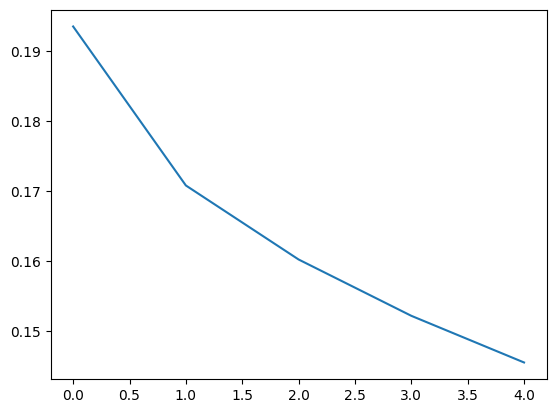

In [37]:
plt.plot(training_loss)

In [38]:
manager = WeightManager(
    artifact_path.joinpath(
        "characeter-aware.{dataset_name}.epoch.{epoch}.pth"
    ).as_posix()
)
model_path = manager.get_filename(dataset_name=DATASET_NAME, epoch=EPOCHS)
model_path

WindowsPath('../../artifacts/character-aware/characeter-aware.wikitext-2-raw-v1.epoch.5.pth')

In [39]:
torch.save(model.state_dict(), model_path)

In [40]:
get_file_size(model_path)

'32.72MiB'

In [41]:
model.load_state_dict(torch.load(model_path))

<All keys matched successfully>

# Evaluation


In [42]:
val_dataset = load_dataset(
    "Salesforce/wikitext", name=DATASET_NAME, cache_dir=data_path, split="validation"
)

In [43]:
val_dataset = dataset_factory(
    val_dataset,
    MINIMUM_LENGTH,
    ngram_transform,
    word_transform,
    word_spans_transform,
)

In [44]:
val_dataloader = DataLoader(
    val_dataset.with_format("torch"),
    batch_size=BATCH_SIZE,
    pin_memory=True,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

## predict next token

In [45]:
from torchmetrics.text import Perplexity
from torchlake.common.controller.evaluator import RegressionEvaluator

In [46]:
metric = Perplexity(ignore_index=CONTEXT.padding_idx).to(DEVICE)

In [47]:
evaluator = RegressionEvaluator(DEVICE, feature_dim=-1)
evaluator.set_predict_strategy(True, 1)

In [48]:
evaluator.run(val_dataloader, model, metric=metric)

100%|██████████| 57/57 [00:27<00:00,  2.04it/s]


Perplexity()

In [49]:
metric.compute()

tensor(163.4364, device='cuda:0')

In [50]:
ngrams, words, word_spans = ngram_tokenizer("Where are you going?")
sample = torch.tensor(
    ngram_vocab.lookup_indices([CONTEXT.bos_str, *ngrams, CONTEXT.eos_str]),
    dtype=torch.long,
    device=DEVICE,
)

model.eval()
with torch.no_grad():
    pred = model([sample], [torch.tensor([1, *word_spans, 1], device=DEVICE)])
    pred = pred.argmax(-1)
    pred = pred[0].tolist()
    pred = vocab.lookup_tokens(pred)

for i, p in enumerate(pred[: len(word_spans) + 1]):
    print(words[: i + 1], p)

['where'] the
['where', 'are'] the
['where', 'are', 'you'] not
['where', 'are', 'you', 'going'] <unk>
['where', 'are', 'you', 'going', '?'] to
['where', 'are', 'you', 'going', '?'] to


## generation

In [51]:
from torchlake.sequence_data.models.base import RNNGenerator

## word analogy


In [52]:
from torchlake.language_model.datasets import WordAnalogyDataset

In [53]:
analogy_data_path = Path("../../data") / "word-analogy"

In [54]:
dataset = WordAnalogyDataset(analogy_data_path)

In [55]:
dataset.data[:20]

[('Athens', 'Greece', 'Baghdad', 'Iraq'),
 ('Athens', 'Greece', 'Bangkok', 'Thailand'),
 ('Athens', 'Greece', 'Beijing', 'China'),
 ('Athens', 'Greece', 'Berlin', 'Germany'),
 ('Athens', 'Greece', 'Bern', 'Switzerland'),
 ('Athens', 'Greece', 'Cairo', 'Egypt'),
 ('Athens', 'Greece', 'Canberra', 'Australia'),
 ('Athens', 'Greece', 'Hanoi', 'Vietnam'),
 ('Athens', 'Greece', 'Havana', 'Cuba'),
 ('Athens', 'Greece', 'Helsinki', 'Finland'),
 ('Athens', 'Greece', 'Islamabad', 'Pakistan'),
 ('Athens', 'Greece', 'Kabul', 'Afghanistan'),
 ('Athens', 'Greece', 'London', 'England'),
 ('Athens', 'Greece', 'Madrid', 'Spain'),
 ('Athens', 'Greece', 'Moscow', 'Russia'),
 ('Athens', 'Greece', 'Oslo', 'Norway'),
 ('Athens', 'Greece', 'Ottawa', 'Canada'),
 ('Athens', 'Greece', 'Paris', 'France'),
 ('Athens', 'Greece', 'Rome', 'Italy'),
 ('Athens', 'Greece', 'Stockholm', 'Sweden')]

### output embedding

In [56]:
tokens = [[vocab[word.lower()] for word in pairs] for pairs in dataset.data]
tokens = torch.LongTensor([token for token in tokens if len(token) == 4])
tokens[:10]

tensor([[13188,  7030, 18709,  5345],
        [13188,  7030,  9110,  6531],
        [13188,  7030, 10409,  1348],
        [13188,  7030,  4715,  1273],
        [13188,  7030,     0,  4431],
        [13188,  7030, 14278,  2287],
        [13188,  7030, 16955,   481],
        [13188,  7030, 14582,  1553],
        [13188,  7030, 17430,  6426],
        [13188,  7030,     0,  6623]])

In [57]:
model.eval()
with torch.no_grad():
    embedder = model.output_embedding
    embedder.eval()
    vectors = embedder(tokens)

In [58]:
vectors.shape

torch.Size([19544, 4, 300])

In [ ]:
# epoch 5: output: 0.1576
# epoch 10: output: 0.13
metric = nn.CosineSimilarity()

country_a, capital_a, country_b, capital_b = vectors.transpose(0, 1)
score = metric(country_a - capital_a - country_b, -capital_b)
print(score.mean().item())

0.15927450358867645


### input embedding

In [65]:
pairs = [" ".join(pairs).lower() for pairs in dataset.data if len(pairs) == 4]
tokens = []
for pair in pairs:
    ngrams, _, word_spans = ngram_tokenizer(pair)
    ngrams = ngram_transform(ngrams)[1:-1].to(DEVICE)
    word_spans = word_spans_transform(word_spans)[1:-1].to(DEVICE)
    tokens.append(([ngrams], [word_spans]))

tokens[:5]

[([tensor([ 21,  10,  12,   4,   8,  15,  57,   9,   4,   4,  20,  11,  36,   6,
            35,  12,  29,   6,  18,  26,   9,   6, 177], device='cuda:0')],
  [tensor([6, 6, 7, 4], device='cuda:0')]),
 ([tensor([21, 10, 12,  4,  8, 15, 57,  9,  4,  4, 20, 11, 36,  6,  8, 35, 58,  7,
           68, 13, 12,  6,  5, 14,  6,  8, 18], device='cuda:0')],
  [tensor([6, 6, 7, 8], device='cuda:0')]),
 ([tensor([21, 10, 12,  4,  8, 15, 57,  9,  4,  4, 20, 11, 36,  4,  5, 90,  5,  8,
           44, 32, 12,  5,  8, 60], device='cuda:0')],
  [tensor([6, 6, 7, 5], device='cuda:0')]),
 ([tensor([21, 10, 12,  4,  8, 15, 57,  9,  4,  4, 20, 11, 36,  4,  9, 14,  5, 19,
           57,  4,  9, 23,  6,  8, 31], device='cuda:0')],
  [tensor([6, 6, 6, 7], device='cuda:0')]),
 ([tensor([21, 10, 12,  4,  8, 15, 57,  9,  4,  4, 20, 11, 36,  4,  9, 19, 24, 54,
            5, 10, 85,  4,  9, 14,  6,  8, 18], device='cuda:0')],
  [tensor([ 6,  6,  4, 11], device='cuda:0')])]

In [66]:
vectors = []

model.eval()
with torch.no_grad():
    # this is input_embedding
    for token in tokens:
        vectors.append(model.get_word_vectors(*token)[0])

vectors = torch.stack(vectors)

In [67]:
vectors.shape

torch.Size([19544, 4, 525])

In [ ]:
# epoch 5: output: 0.8753
# epoch 10: output: 0.8156
metric = nn.CosineSimilarity()

country_a, capital_a, country_b, capital_b = vectors.transpose(0, 1)
score = metric(country_a - capital_a - country_b, -capital_b)
print(score.mean().item())

0.8752626776695251
